#Analysis of *Anopheles* sp. distribution in Malaric-endemic Countries

We decided to compare recorded ocurrences of Anopheles sp. mosquitoes in [gbif.org](https://www.gbif.org/) with published literature regarding distribution of dominant malaria vectors in malaria-endemic countries of Africa and South America. We then chose one country from each of the two continents for a deeper analysis.

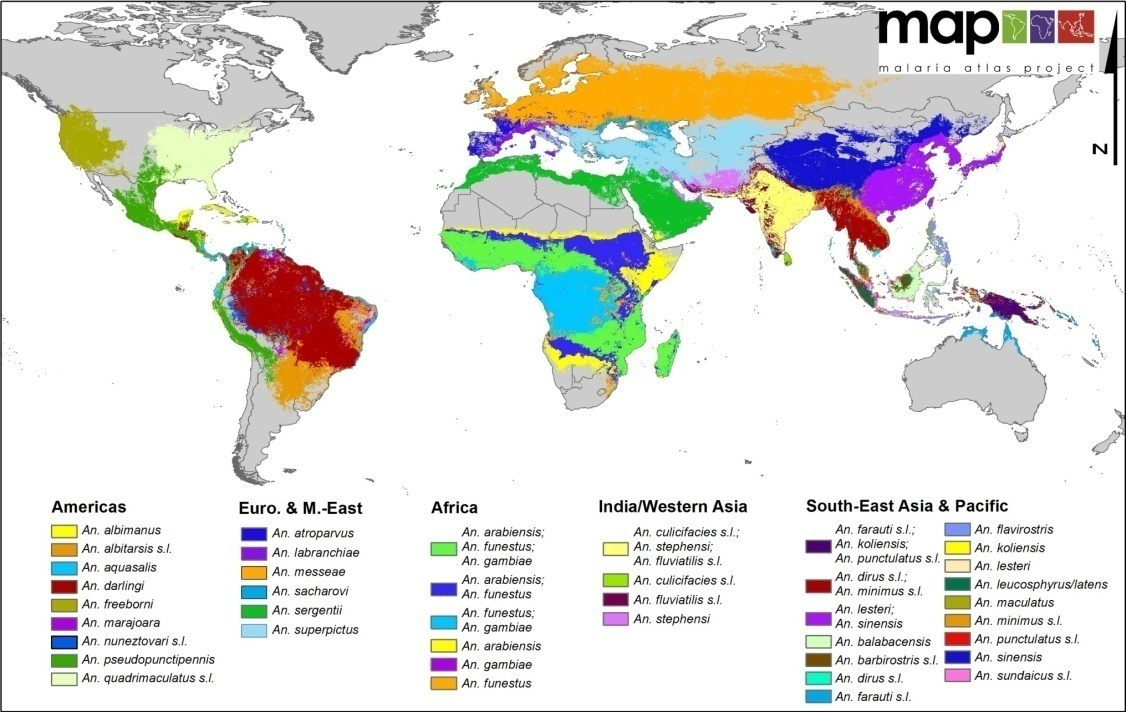

**Source:** Sinka, M.E., Bangs, M.J., Manguin, S. et al. A global map of dominant malaria vectors. Parasites Vectors 5, 69 (2012). https://doi.org/10.1186/1756-3305-5-69

In [ ]:
!pip install pygbif

In [ ]:
from pygbif import species as species
from pygbif import occurrences as occ
import pygbif
pygbif.caching(True)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import math
import folium
from folium import Choropleth, Circle, Marker
from folium.plugins import HeatMap, MarkerCluster

First, we got the species key for all 41 dominant malaria vectors according to Sinka et al.

In [ ]:
#get species codes for dominant vectors of human malaria

splist = [
    "Anopheles aconitus",
    "Anopheles albimanus",
    "Anopheles albitarsis",
    "Anopheles annularis",
    "Anopheles aquasalis",
    "Anopheles arabiensis",
    "Anopheles atroparvus",
    "Anopheles balabacensis",
    "Anopheles barbirostris",
    "Anopheles culicifacies",
    "Anopheles darlingi",
    "Anopheles dirus",
    "Anopheles farauti",
    "Anopheles flavirostris",
    "Anopheles freeborni",
    "Anopheles fluviatilis",
    "Anopheles funestus",
    "Anopheles gambiae",
    "Anopheles koliensis",
    "Anopheles labranchiae",
    "Anopheles leucosphyrus",
    "Anopheles lesteri",
    "Anopheles maculatus",
    "Anopheles marajoara",
    "Anopheles melas",
    "Anopheles merus",
    "Anopheles messeae",
    "Anopheles minimus",
    "Anopheles moucheti",
    "Anopheles nili",
    "Anopheles nuneztovari",
    "Anopheles pseudopunctipennis",
    "Anopheles punctulatus",
    "Anopheles quadrimaculatus",
    "Anopheles sacharovi",
    "Anopheles sergentii",
    "Anopheles sinensis",
    "Anopheles stephensi",
    "Anopheles superpictus"
]


keys = [species.name_backbone(x)['usageKey'] for x in splist]
keys

[1650368,
 1650361,
 1650685,
 1650463,
 1650387,
 1650772,
 1650503,
 1650249,
 1650580,
 1650474,
 1650149,
 1650124,
 1650225,
 1650636,
 1650116,
 1650633,
 1650158,
 1650518,
 1650870,
 1650739,
 1650125,
 1650344,
 1650755,
 1650776,
 1650594,
 1650398,
 1650482,
 1650618,
 1650177,
 1650675,
 1650135,
 1650450,
 1650849,
 1650395,
 1650573,
 1650851,
 1650357,
 1650441,
 1650284]

We focused on the top 5 countries with the most malaria cases in both the WHO African Region and Region of the Americas, according to the World Health Organization's World Malaria Report 2024. 95% of malaria cases are registered in Sub-Saharan Africa. However, we wanted to explore two regions with different *Anopheles* species composition.

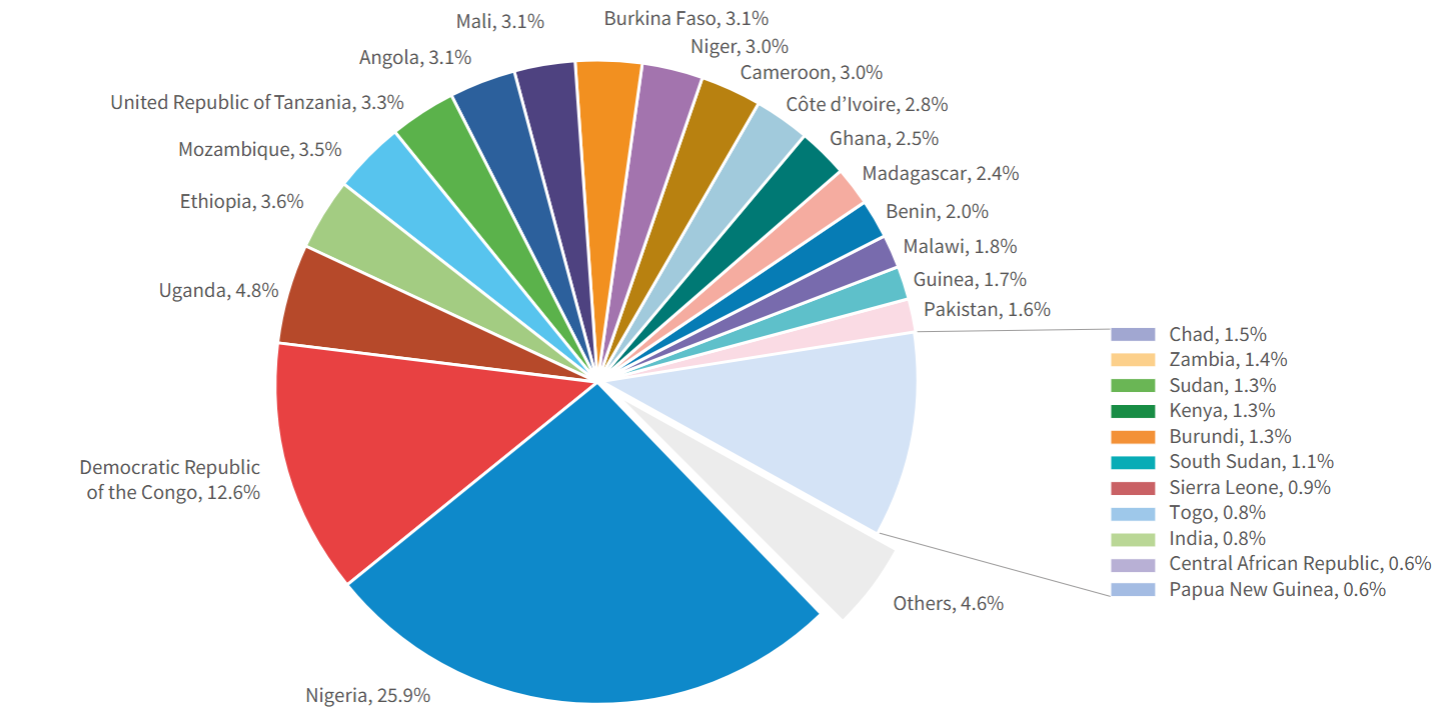

Malaria cases in the Region of the Americas:
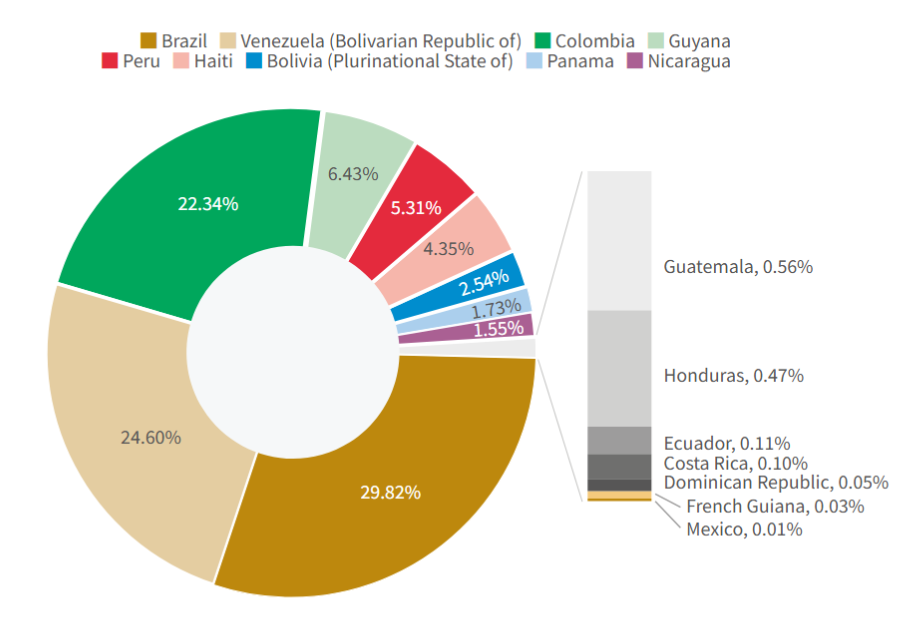

In [ ]:
#get records of Anopheles species found in the top 5 African and American countries in malaria cases (WHO World Malaria Report 2024)

species_counts = {
    'NG': {},  # Nigeria
    'CD': {},  # RDC
    'UG': {},  # Uganda
    'ET': {},  # Ethiopia
    'MZ': {},  # Mozambique
    'BR': {},  # Brazil
    'VE': {},  # Venezuela
    'CO': {},  # Colombia
    'GY': {},  # Guyana
    'PE': {}   # Peru
}

# Iterate over the 10 countries and all species
for taxon in keys:
    for country_code in species_counts:
        count = occ.search(country=country_code, taxonKey=taxon, limit=0)['count']
        if count > 0:
            species_counts[country_code][taxon] = count

# Sort species per country by count (descending)
sorted_species_counts = {
    country: dict(sorted(taxon_counts.items(), key=lambda item: item[1], reverse=True))
    for country, taxon_counts in species_counts.items()
}

country_names = {
    'NG': 'Nigeria',
    'CD': 'RDC',
    'UG': 'Uganda',
    'ET': 'Ethiopia',
    'MZ': 'Mozambique',
    'BR': 'Brazil',
    'VE': 'Venezuela',
    'CO': 'Colombia',
    'GY': 'Guyana',
    'PE': 'Peru'
}

#Print results per country, per species
taxon_name_map = {}
for taxon in keys:
    info = species.name_usage(key=taxon, data="all")
    sci_name = info.get("canonicalName")
    taxon_name_map[taxon] = sci_name

for country_code, species_dict in sorted_species_counts.items():
    total_records = sum(species_dict.values())
    print(f"\nSpecies recorded in {country_names[country_code]} ({total_records} records total):")
    for taxon, count in species_dict.items():
        species_name = taxon_name_map.get(taxon)
        print(f"  {species_name} ({taxon}): {count} records")


Species recorded in Nigeria (204 records total):
  Anopheles gambiae (1650518): 77 records
  Anopheles arabiensis (1650772): 69 records
  Anopheles nili (1650675): 27 records
  Anopheles moucheti (1650177): 20 records
  Anopheles funestus (1650158): 8 records
  Anopheles melas (1650594): 2 records
  Anopheles stephensi (1650441): 1 records

Species recorded in RDC (4254 records total):
  Anopheles gambiae (1650518): 3988 records
  Anopheles funestus (1650158): 211 records
  Anopheles nili (1650675): 41 records
  Anopheles moucheti (1650177): 11 records
  Anopheles arabiensis (1650772): 2 records
  Anopheles melas (1650594): 1 records

Species recorded in Uganda (36376 records total):
  Anopheles gambiae (1650518): 28679 records
  Anopheles funestus (1650158): 5690 records
  Anopheles arabiensis (1650772): 2007 records

Species recorded in Ethiopia (3131 records total):
  Anopheles gambiae (1650518): 1587 records
  Anopheles funestus (1650158): 1450 records
  Anopheles arabiensis (1650

Distinguishing between total records and records with coordinates (latitude and longitude) and plotting results by country.

In [ ]:
#Add up all records, for each country
country_totals = {
    country_names[country_code]: sum(species_counts[country_code].values())
    for country_code in species_counts
}


#Add up records with coordinates, for each country
NG_coords = [occ.search(taxonKey=keys, country='NG', hasCoordinate=True, limit=0)['count']]
CD_coords = [occ.search(taxonKey=keys, country='CD', hasCoordinate=True, limit=0)['count']]
UG_coords = [occ.search(taxonKey=keys, country='UG', hasCoordinate=True, limit=0)['count']]
ET_coords = [occ.search(taxonKey=keys, country='ET', hasCoordinate=True, limit=0)['count']]
MZ_coords = [occ.search(taxonKey=keys, country='MZ', hasCoordinate=True, limit=0)['count']]

BR_coords = [occ.search(taxonKey=keys, country='BR', hasCoordinate=True, limit=0)['count']]
VE_coords = [occ.search(taxonKey=keys, country='VE', hasCoordinate=True, limit=0)['count']]
CO_coords = [occ.search(taxonKey=keys, country='CO', hasCoordinate=True, limit=0)['count']]
GY_coords = [occ.search(taxonKey=keys, country='GY', hasCoordinate=True, limit=0)['count']]
PE_coords = [occ.search(taxonKey=keys, country='PE', hasCoordinate=True, limit=0)['count']]

country_with_coordinates = {
    'Nigeria': NG_coords[0],
    'RDC': CD_coords[0],
    'Uganda': UG_coords[0],
    'Ethiopia': ET_coords[0],
    'Mozambique': MZ_coords[0],
    'Brazil': BR_coords[0],
    'Venezuela': VE_coords[0],
    'Colombia': CO_coords[0],
    'Guyana': GY_coords[0],
    'Peru': PE_coords[0],
}


#Join with total counts in a dataframe
data = []
for country, total in country_totals.items():
    with_coords = country_with_coordinates.get(country, 0)
    data.append({'Country': country, 'Count': total, 'Type': 'Total Records'})
    data.append({'Country': country, 'Count': with_coords, 'Type': 'With Coordinates'})

df_long = pd.DataFrame(data)


# Define regions (African VS. Americas)
african_countries = ['Nigeria', 'RDC', 'Uganda', 'Ethiopia', 'Mozambique']
american_countries = ['Brazil', 'Venezuela', 'Colombia', 'Guyana', 'Peru']
all_countries = african_countries + american_countries

df_long['Region'] = df_long['Country'].apply(
    lambda x: 'African Region' if x in african_countries else 'Region of the Americas'
)
df_long['Region_Type'] = df_long['Region'] + ' - ' + df_long['Type']


# Sort countries by total records (descending)
country_order = (
    df_long[df_long['Type'] == 'Total Records']
    .sort_values(by='Count', ascending=False)['Country']
    .tolist()
)


# Define colors from tab20 palette
tab20 = plt.get_cmap('tab20').colors
palette = {
    'African Region - Total Records': tab20[0],
    'African Region - With Coordinates': tab20[1],
    'Region of the Americas - Total Records': tab20[2],
    'Region of the Americas - With Coordinates': tab20[3],
}


# Extract values and colors for bars
total_counts = []
coord_counts = []
total_colors = []
coord_colors = []

for country in country_order:
    total_row = df_long[(df_long['Country'] == country) & (df_long['Type'] == 'Total Records')].iloc[0]
    coord_row = df_long[(df_long['Country'] == country) & (df_long['Type'] == 'With Coordinates')].iloc[0]

    total_counts.append(total_row['Count'])
    coord_counts.append(coord_row['Count'])

    total_colors.append(palette[total_row['Region_Type']])
    coord_colors.append(palette[coord_row['Region_Type']])


df_long

,Country,Count,Type,Region,Region_Type
0,Nigeria,204,Total Records,African Region,African Region - Total Records
1,Nigeria,185,With Coordinates,African Region,African Region - With Coordinates
2,RDC,4254,Total Records,African Region,African Region - Total Records
3,RDC,4189,With Coordinates,African Region,African Region - With Coordinates
4,Uganda,36376,Total Records,African Region,African Region - Total Records
5,Uganda,36310,With Coordinates,African Region,African Region - With Coordinates
6,Ethiopia,3131,Total Records,African Region,African Region - Total Records
7,Ethiopia,3118,With Coordinates,African Region,African Region - With Coordinates
8,Mozambique,13592,Total Records,African Region,African Region - Total Records
9,Mozambique,13431,With Coordinates,African Region,African Region - With Coordinates


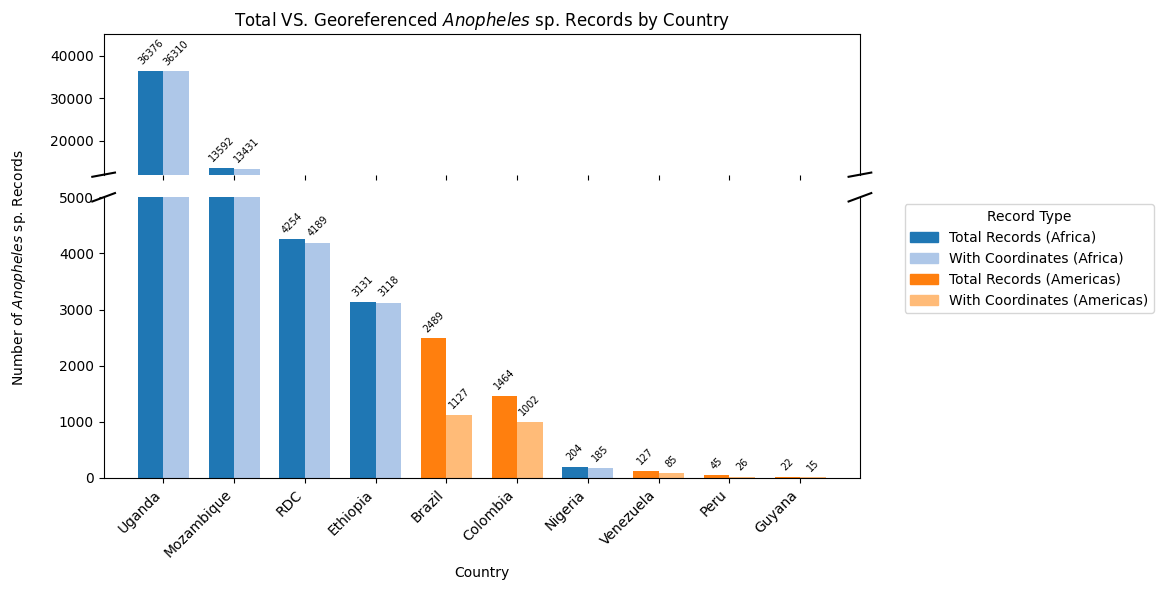

In [ ]:
#Bar plot with broken y axis
fig, (ax_top, ax_bottom) = plt.subplots(2, 1, sharex=True, figsize=(12, 6),
                                        gridspec_kw={'height_ratios': [1, 2]})

#Bar and group spacing
bar_width = 0.9
group_gap = 0.7
group_width = 2 * bar_width + group_gap

x = np.arange(len(country_order)) * group_width


ax_bottom.bar(x - bar_width/2, total_counts, width=bar_width, color=total_colors)
ax_bottom.bar(x + bar_width/2, coord_counts, width=bar_width, color=coord_colors)

ax_top.bar(x - bar_width/2, total_counts, width=bar_width, color=total_colors)
ax_top.bar(x + bar_width/2, coord_counts, width=bar_width, color=coord_colors)


#Broken y-axis limits
ax_top.set_ylim(12000, 45000)
ax_bottom.set_ylim(0, 5000)


#Hide border between plots
ax_top.spines['bottom'].set_visible(False)
ax_bottom.spines['top'].set_visible(False)


#Hide x axis labels on the top plot
ax_top.tick_params(labeltop=False)
ax_bottom.xaxis.tick_bottom()

ax_bottom.set_xticks(x)
ax_bottom.set_xticklabels(country_order, rotation=45, ha='right')


#Diagonal lines to indicate broken axis
d = .015
diagonals = dict(transform=ax_top.transAxes, color='k', clip_on=False)
ax_top.plot((-d, +d), (-d, +d), **diagonals)
ax_top.plot((1 - d, 1 + d), (-d, +d), **diagonals)
diagonals.update(transform=ax_bottom.transAxes)
ax_bottom.plot((-d, +d), (1 - d, 1 + d), **diagonals)
ax_bottom.plot((1 - d, 1 + d), (1 - d, 1 + d), **diagonals)


#Add counts on top of bars
for ax in [ax_top, ax_bottom]:
    for i, (tc, cc) in enumerate(zip(total_counts, coord_counts)):
        for val, xpos in zip([tc, cc], [x[i] - bar_width/2, x[i] + bar_width/2]):
            ax.annotate(
                f'{int(val)}',
                (xpos, val),
                ha='center',
                va='bottom',
                fontsize=7,
                rotation=45,
                xytext=(0, 3),
                textcoords='offset points'
            )


#Legend
handles = [
    mpatches.Patch(color=tab20[0], label='Total Records (Africa)'),
    mpatches.Patch(color=tab20[1], label='With Coordinates (Africa)'),
    mpatches.Patch(color=tab20[2], label='Total Records (Americas)'),
    mpatches.Patch(color=tab20[3], label='With Coordinates (Americas)')
]
ax_bottom.legend(handles=handles, title='Record Type', bbox_to_anchor=(1.05, 1), loc='upper left')

#Axis labels
ax_bottom.set_ylabel('Number of $\\it{Anopheles}$ sp. Records')
ax_bottom.yaxis.set_label_coords(-0.1, 0.75)
ax_bottom.set_xlabel('Country')
ax_top.set_title('Total VS. Georeferenced $\\it{Anopheles}$ sp. Records by Country')

plt.tight_layout()
plt.show()

Checking species diversity by country.

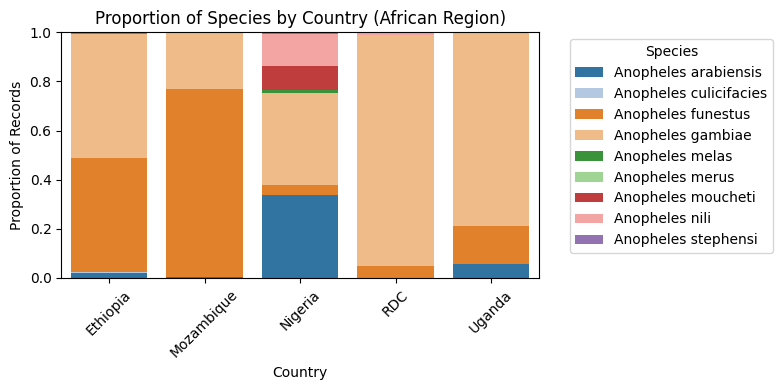

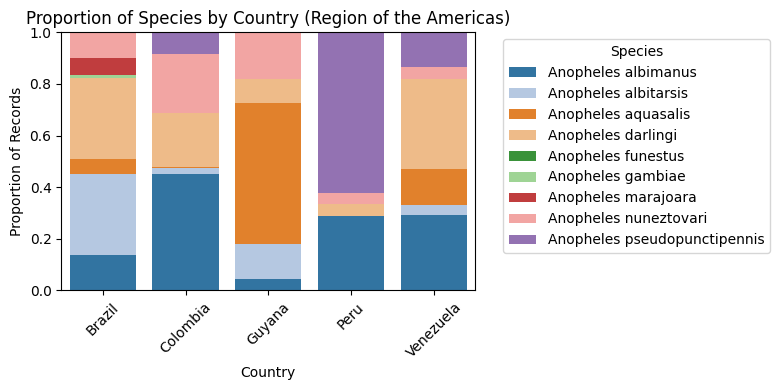

In [ ]:
#plot species proportion by country & region

#Transform counts into proportion of species by country
data = []
for country_code, species_dict in sorted_species_counts.items():
    total = sum(species_dict.values())
    country_name = country_names.get(country_code, country_code)
    for taxon, count in species_dict.items():
        species_name = taxon_name_map.get(taxon, f"TaxonKey {taxon}")
        proportion = count / total if total > 0 else 0
        data.append({
            'Country': country_name,
            'Species': species_name,
            'Proportion': proportion
        })

df_prop = pd.DataFrame(data)


#Plot function
def plot_region(df_region, region_title):
    df_stacked = df_region.pivot_table(
        index='Country',
        columns='Species',
        values='Proportion',
        aggfunc='sum',
        fill_value=0
    ).reset_index()

    fig, ax = plt.subplots(figsize=(8, 4))
    bottom = pd.Series([0] * df_stacked.shape[0])
    x = df_stacked['Country']
    colors = sns.color_palette('tab20', n_colors=len(df_stacked.columns) - 1)

    for i, species in enumerate(df_stacked.columns[1:]):
        y = df_stacked[species]
        sns.barplot(x=x, y=y, color=colors[i], ax=ax, bottom=bottom, label=species)
        bottom += y

    ax.set_ylabel('Proportion of Records')
    ax.set_xlabel('Country')
    ax.set_title(f'Proportion of Species by Country ({region_title})')
    ax.legend(title='Species', bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()


#Generate plots
plot_region(df_prop[df_prop['Country'].isin(african_countries)], 'African Region')
plot_region(df_prop[df_prop['Country'].isin(american_countries)], 'Region of the Americas')

As expected, species composition was distinct between the two continents. Brazil showed the highest amount of species, including the African A. gambiae and A. funestus. All African countries showed low diversity in recorded species, with the exception of Nigeria (204 total records).

Mozambique and Brazil were chosen as representatives of the African and American continents, respectively, for the following analysis.